# Tiling experiment — native-resolution 640×640 crops

Stage-2 experiment of the project ([docs/proposal.md](../docs/proposal.md)):
**does tiled inference at native resolution improve small-object detection over the
640 full-image baseline, and what does it cost?**

The two stage-1 fine-tuned checkpoints (`yolo26m`, `yolo26x`) are reused **unchanged**
— training stays at `imgsz=640`; only inference changes. Each native-resolution image
is sliced into 640×640 crops with the requested overlap, every crop is fed to the
detector, predictions are mapped back to original-image coordinates and merged with
class-aware NMS. Scoring uses the same single evaluator
[`src/evaluation/metrics.py`](../src/evaluation/metrics.py) called with
`inference="tiled"`, so every metric matches the baseline protocol exactly.

Reported here:

1. the main tiling condition (**20 % overlap**) for **both models**, with **all metrics**
   (mAP50–95, mAP50, recall, tiny + COCO size-group AP/recall + object counts, runtime);
2. the tile-overlap sensitivity sweep (0 % / 20 % / 40 %) for `yolo26m`;
3. the accuracy–runtime trade-off against the 640 full-image baseline.


## 1. Setup

Fixed protocol constants (must not change once results are examined) plus the
checkpoint paths. **To evaluate later fine-tuned weights, only edit `WEIGHTS` below**
— everything else stays identical.


In [1]:
from __future__ import annotations

import sys
import time
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from PIL import Image
from ultralytics import YOLO

# ---- fixed protocol (identical to the baseline) --------------------------- #
SEED = 42
CONF_EVAL = 0.001  # AP confidence
CONF_RECALL = 0.25  # recall confidence
IOU_RECALL = 0.5  # recall IoU
IOU_NMS = 0.7  # NMS IoU, fixed for every condition (cross-tile merge too)

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.evaluation.metrics import (
    TILE_SIZE,
    evaluate_split,
    load_split_paths,
    predict_image_tiled,
    read_yolo_labels,
    tile_starts,
    yolo_to_xyxy,
)

# ---- tiling condition ------------------------------------------------------#
SPLIT = "test"  # test-dev, 1,610 images (val is selection-only)
TILE = TILE_SIZE  # 640x640 native-resolution crops
MAIN_OVERLAP = 0.20  # main tiling condition (proposal)
OVERLAP_SWEEP = [0.0, 0.20, 0.40]  # yolo26m sensitivity sweep (proposal)
RUNTIME_IMAGES = 200  # images used for the timed pass (mean/p95 per image)

# ---- checkpoints: point these at the weights you want to evaluate ----------#
# Default: the stage-1 fine-tuned checkpoints from the baseline notebook.
RUNS_DIR = ROOT / "runs"
STAGE1_DIR = RUNS_DIR / "baseline"
WEIGHTS: dict[str, Path] = {
    "yolo26m": STAGE1_DIR / "yolo26m_s640" / "weights" / "best.pt",
    "yolo26x": STAGE1_DIR / "yolo26x_s640" / "weights" / "best.pt",
}
# After the full fine-tune, load the modified weights by overriding, e.g.:
# WEIGHTS = {
#     "yolo26m": RUNS_DIR / "finetune" / "yolo26m" / "weights" / "best.pt",
#     "yolo26x": RUNS_DIR / "finetune" / "yolo26x" / "weights" / "best.pt",
# }

TILING_DIR = RUNS_DIR / "tiling"
TILING_DIR.mkdir(parents=True, exist_ok=True)
BASELINE_CSV = STAGE1_DIR / f"baseline_scores_{SPLIT}_640.csv"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"root={ROOT}")
print(f"device={DEVICE}")
if DEVICE == "cuda":
    print(f"gpu={torch.cuda.get_device_name(0)}")
for name, path in WEIGHTS.items():
    print(f"{name}: {path} ({'found' if path.exists() else 'MISSING'})")

root=/home/danil/Documents/CV/small-object-detection
device=cuda
gpu=NVIDIA GeForce RTX 4060 Laptop GPU
yolo26m: /home/danil/Documents/CV/small-object-detection/runs/baseline/yolo26m_s640/weights/best.pt (found)
yolo26x: /home/danil/Documents/CV/small-object-detection/runs/baseline/yolo26x_s640/weights/best.pt (found)


In [2]:
def load_checkpoints(weights: dict[str, Path]) -> dict[str, YOLO]:
    """Load every checkpoint; fail early if a path is wrong."""
    models: dict[str, YOLO] = {}
    for name, path in weights.items():
        if not Path(path).exists():
            raise FileNotFoundError(f"{name}: checkpoint not found at {path}")
        models[name] = YOLO(str(path))
        print(f"{name}: loaded {len(models[name].names)} classes from {path}")
    return models


checkpoints = load_checkpoints(WEIGHTS)

yolo26m: loaded 10 classes from /home/danil/Documents/CV/small-object-detection/runs/baseline/yolo26m_s640/weights/best.pt


yolo26x: loaded 10 classes from /home/danil/Documents/CV/small-object-detection/runs/baseline/yolo26x_s640/weights/best.pt


## 2. Tiling geometry sanity check

`tile_starts` covers the whole image with `tile`-sized windows at stride
`tile * (1 - overlap)`; the last window is flush with the far edge. The grid below
is what every image is sliced into (3 tile sizes shown for the three sweep values).


In [3]:
def tile_grid(width: int, height: int, tile: int = TILE, overlap: float = MAIN_OVERLAP):
    xs = tile_starts(width, tile, overlap)
    ys = tile_starts(height, tile, overlap)
    return xs, ys


for overlap in OVERLAP_SWEEP:
    xs, ys = tile_grid(1360, 765, overlap=overlap)
    print(
        f"overlap {overlap:.0%}: xs={xs} ys={ys} -> {len(xs) * len(ys)} tiles for a 1360x765 image"
    )

overlap 0%: xs=[0, 640, 720] ys=[0, 125] -> 6 tiles for a 1360x765 image
overlap 20%: xs=[0, 512, 720] ys=[0, 125] -> 6 tiles for a 1360x765 image
overlap 40%: xs=[0, 384, 720] ys=[0, 125] -> 6 tiles for a 1360x765 image


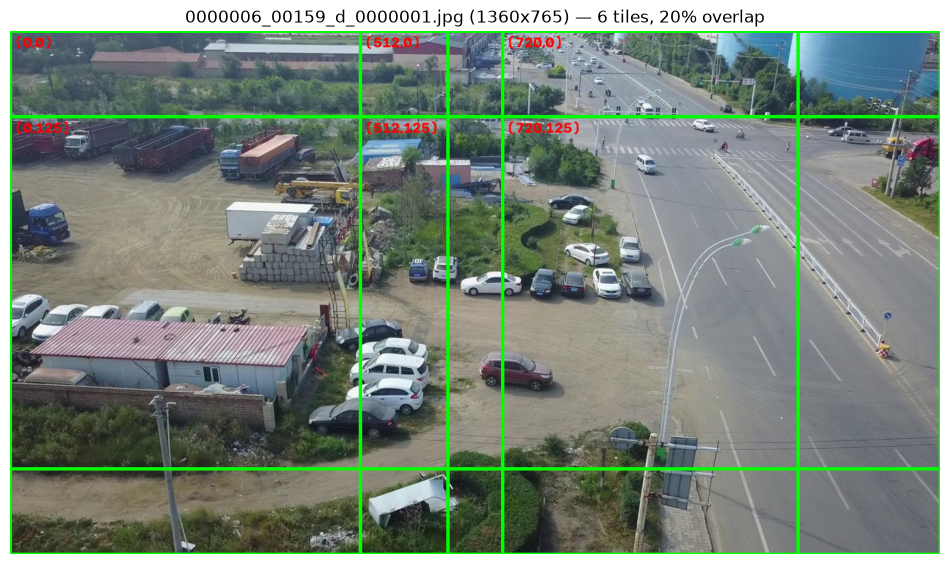

In [4]:
def show_tiles(index: int = 0, overlap: float = MAIN_OVERLAP) -> None:
    """Draw the tile grid and its origins on one native-resolution image."""
    images, _ = load_split_paths(SPLIT)
    import cv2

    image_path = images[index]
    img = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    height, width = img.shape[:2]
    xs, ys = tile_grid(width, height, overlap=overlap)
    for y0 in ys:
        for x0 in xs:
            cv2.rectangle(img, (x0, y0), (x0 + TILE, y0 + TILE), (0, 255, 0), 3)
            cv2.putText(
                img,
                f"({x0},{y0})",
                (x0 + 6, y0 + 24),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (255, 0, 0),
                2,
            )
    plt.figure(figsize=(12, 9))
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"{image_path.name} ({width}x{height}) — {len(xs) * len(ys)} tiles, {overlap:.0%} overlap"
    )
    plt.show()


show_tiles(0, overlap=MAIN_OVERLAP)

## 3. Tiled evaluation

`evaluate_split(..., inference="tiled", tile=640, overlap=...)` slices each image,
runs the detector on every crop, maps boxes back to original coordinates, merges
them with class-aware NMS at the fixed IoU 0.7, drops predictions overlapping
ignored regions, and scores **all metrics** with the shared evaluator. The runtime
pass counts image decode, all tiles, inference and merging (batch size 1, warm-up,
CUDA sync).


In [5]:
def run_tiled_eval(
    models: dict[str, YOLO],
    overlap: float = MAIN_OVERLAP,
    split: str = SPLIT,
    tile: int = TILE,
    runtime_images: int | None = RUNTIME_IMAGES,
) -> pd.DataFrame:
    """Tiled evaluation for every model at one overlap; writes one CSV per overlap."""
    images, labels = load_split_paths(split)
    rows: list[dict[str, Any]] = []
    for name, model in models.items():
        print(
            f"=== {name} tiled {tile}x{tile} overlap={overlap:.0%} @ {split} ({len(images)} images) ==="
        )
        start = time.perf_counter()
        metrics = evaluate_split(
            labels=labels,
            images=images,
            model=model,
            inference="tiled",
            tile=tile,
            overlap=overlap,
            conf=CONF_EVAL,
            runtime_images=runtime_images,
        )
        elapsed = time.perf_counter() - start
        rows.append(
            {
                "model": name,
                "weights": str(WEIGHTS[name]),
                "split": split,
                "inference": "tiled",
                "tile": tile,
                "overlap": overlap,
                "imgsz": tile,
                "runtime_images": len(images)
                if runtime_images is None
                else min(runtime_images, len(images)),
                **metrics,
            }
        )
        print(
            f"    mAP50-95={metrics['map50_95']:.4f} mAP50={metrics['map50']:.4f} "
            f"recall={metrics['recall50_25']:.4f} tiny_AP={metrics['ap_tiny']:.4f} "
            f"tiny_recall={metrics['recall_tiny']:.4f} "
            f"runtime={metrics['runtime_mean_ms']:.1f}ms ({elapsed:.0f}s total)"
        )
    table = pd.DataFrame(rows)
    out = TILING_DIR / f"tiling_scores_{split}_ov{round(overlap * 100):02d}.csv"
    table.to_csv(out, index=False)
    print(f"saved -> {out}")
    return table

### 3.1 Main condition — 20 % overlap, both models

This is the proposal's main tiling condition. All metrics are reported for
`yolo26m` and `yolo26x`.


In [6]:
main_scores = run_tiled_eval(checkpoints, overlap=MAIN_OVERLAP, split=SPLIT)
display(main_scores.T)

=== yolo26m tiled 640x640 overlap=20% @ test (1610 images) ===


creating index...
index created!


Loading and preparing results...


DONE (t=3.16s)
creating index...


index created!
Running per image evaluation...
Evaluate annotation type *bbox*


...

index created!
Running per image evaluation...
Evaluate annotation type *bbox*


DONE (t=121.09s).
Accumulating evaluation results...


DONE (t=6.73s).


    mAP50-95=0.2252 mAP50=0.3857 recall=0.6679 tiny_AP=0.0857 tiny_recall=0.4406 runtime=174.8ms (505s total)
saved -> /home/danil/Documents/CV/small-object-detection/runs/tiling/tiling_scores_test_ov20.csv


,0,1
model,yolo26m,yolo26x
weights,/home/danil/Documents/CV/small-object-detectio...,/home/danil/Documents/CV/small-object-detectio...
split,test,test
inference,tiled,tiled
tile,640,640
overlap,0.2,0.2
imgsz,640,640
runtime_images,200,200
map50_95,0.194842,0.225205
ap_tiny,0.064328,0.08575


### 3.2 Overlap sensitivity sweep — yolo26m (0 % / 20 % / 40 %)

One factor varies (tile overlap), everything else fixed. The 20 % row is reused
from section 3.1 rather than recomputed.


In [7]:
sweep_tables = {MAIN_OVERLAP: main_scores[main_scores["model"] == "yolo26m"]}
for overlap in OVERLAP_SWEEP:
    if overlap == MAIN_OVERLAP:
        continue
    sweep_tables[overlap] = run_tiled_eval(
        {"yolo26m": checkpoints["yolo26m"]}, overlap=overlap, split=SPLIT
    )

overlap_scores = pd.concat([sweep_tables[o] for o in OVERLAP_SWEEP], ignore_index=True)
overlap_scores = overlap_scores.sort_values("overlap").reset_index(drop=True)
overlap_scores.to_csv(TILING_DIR / f"tiling_overlap_sweep_{SPLIT}_yolo26m.csv", index=False)
display(
    overlap_scores[
        [
            "overlap",
            "map50_95",
            "map50",
            "recall50_25",
            "ap_tiny",
            "recall_tiny",
            "ap_small",
            "recall_small",
            "ap_medium",
            "recall_medium",
            "ap_large",
            "recall_large",
            "runtime_mean_ms",
            "runtime_p95_ms",
        ]
    ].round(4)
)

=== yolo26m tiled 640x640 overlap=0% @ test (1610 images) ===


creating index...
index created!


Loading and preparing results...


DONE (t=3.33s)
creating index...


index created!
Running per image evaluation...
Evaluate annotation type *bbox*


...

index created!
Running per image evaluation...
Evaluate annotation type *bbox*


DONE (t=137.82s).
Accumulating evaluation results...


DONE (t=8.74s).


    mAP50-95=0.1953 mAP50=0.3390 recall=0.6359 tiny_AP=0.0644 tiny_recall=0.3884 runtime=85.8ms (332s total)
saved -> /home/danil/Documents/CV/small-object-detection/runs/tiling/tiling_scores_test_ov40.csv


,overlap,map50_95,map50,recall50_25,ap_tiny,recall_tiny,ap_small,recall_small,ap_medium,recall_medium,ap_large,recall_large,runtime_mean_ms,runtime_p95_ms
0,0.0,0.1892,0.3356,0.6203,0.0627,0.3760,0.1169,0.5257,0.2741,0.8205,0.2783,0.8020,63.3448,80.3596
1,0.2,0.1948,0.3393,0.6303,0.0643,0.3849,0.1195,0.5343,0.2831,0.8326,0.2903,0.8211,68.4443,105.8442
2,0.4,0.1953,0.3390,0.6359,0.0644,0.3884,0.1197,0.5395,0.2820,0.8383,0.2894,0.8340,85.7851,196.7012


## 4. Comparison against the 640 full-image baseline

The stage-1 baseline table (`runs/baseline/baseline_scores_test_640.csv`) is loaded
for reference and merged with the 20 % tiling rows. Deltas are
`tiling − baseline`; positive is better for every accuracy metric and worse for runtime.


In [8]:
baseline = pd.read_csv(BASELINE_CSV)
baseline["inference"] = "full-640"
baseline["overlap"] = 0.0
baseline["tile"] = 0

metric_cols = [
    "map50_95",
    "map50",
    "recall50_25",
    "ap_tiny",
    "recall_tiny",
    "ap_small",
    "recall_small",
    "ap_medium",
    "recall_medium",
    "ap_large",
    "recall_large",
    "runtime_mean_ms",
    "runtime_p95_ms",
]
count_cols = ["n_all", "n_tiny", "n_small", "n_medium", "n_large"]

baseline_keep = baseline[["model", "inference", *metric_cols, *count_cols]].copy()
tiling_keep = main_scores[
    ["model", "inference", "tile", "overlap", *metric_cols, *count_cols]
].copy()
comparison = pd.concat([baseline_keep, tiling_keep], ignore_index=True)
comparison.to_csv(TILING_DIR / f"tiling_vs_baseline_{SPLIT}.csv", index=False)

order = [
    "map50_95",
    "map50",
    "recall50_25",
    "ap_tiny",
    "recall_tiny",
    "ap_small",
    "recall_small",
    "ap_medium",
    "recall_medium",
    "ap_large",
    "recall_large",
    "runtime_mean_ms",
    "runtime_p95_ms",
]
delta_rows = []
for model in WEIGHTS:
    base = comparison[(comparison["model"] == model) & (comparison["inference"] == "full-640")]
    tile = comparison[(comparison["model"] == model) & (comparison["inference"] == "tiled")]
    if base.empty or tile.empty:
        continue
    row = {"model": model}
    for col in order:
        row[col] = float(tile.iloc[0][col]) - float(base.iloc[0][col])
    delta_rows.append(row)
deltas = pd.DataFrame(delta_rows).set_index("model")

print("Absolute metrics (tiling 20% vs 640 full-image):")
display(comparison[["model", "inference", *order[:11]]].round(4))
print("Delta (tiling - baseline):")
display(deltas.round(4))

Absolute metrics (tiling 20% vs 640 full-image):


,model,inference,map50_95,map50,recall50_25,ap_tiny,recall_tiny,ap_small,recall_small,ap_medium,recall_medium,ap_large,recall_large
0,yolo26m,full-640,0.1846,0.3080,0.5160,0.0373,0.1965,0.0822,0.3711,0.2813,0.8100,0.5049,0.9066
1,yolo26x,full-640,0.2065,0.3420,0.5542,0.0430,0.2374,0.0969,0.4141,0.3146,0.8394,0.5048,0.9240
2,yolo26m,tiled,0.1948,0.3393,0.6303,0.0643,0.3849,0.1195,0.5343,0.2831,0.8326,0.2903,0.8211
3,yolo26x,tiled,0.2252,0.3857,0.6679,0.0857,0.4406,0.1444,0.5787,0.3250,0.8545,0.3214,0.8568


Delta (tiling - baseline):


,map50_95,map50,recall50_25,ap_tiny,recall_tiny,ap_small,recall_small,ap_medium,recall_medium,ap_large,recall_large,runtime_mean_ms,runtime_p95_ms
model,,,,,,,,,,,,,
yolo26m,0.0103,0.0313,0.1143,0.0270,0.1884,0.0372,0.1633,0.0018,0.0226,-0.2146,-0.0855,55.7645,90.2690
yolo26x,0.0187,0.0437,0.1137,0.0428,0.2031,0.0475,0.1647,0.0104,0.0151,-0.1834,-0.0672,151.4843,233.9805


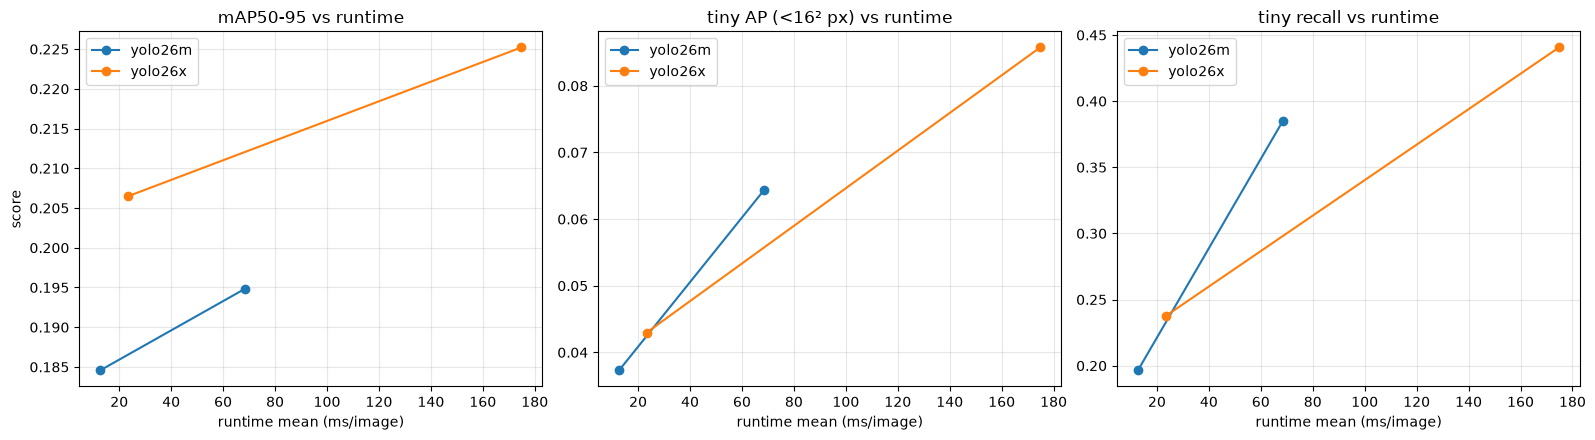

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
colors = {"yolo26m": "tab:blue", "yolo26x": "tab:orange"}

for model in WEIGHTS:
    row_base = comparison[
        (comparison["model"] == model) & (comparison["inference"] == "full-640")
    ].iloc[0]
    row_tile = comparison[
        (comparison["model"] == model) & (comparison["inference"] == "tiled")
    ].iloc[0]

    axes[0].plot(
        [row_base["runtime_mean_ms"], row_tile["runtime_mean_ms"]],
        [row_base["map50_95"], row_tile["map50_95"]],
        "o-",
        color=colors[model],
        label=model,
    )
    axes[1].plot(
        [row_base["runtime_mean_ms"], row_tile["runtime_mean_ms"]],
        [row_base["ap_tiny"], row_tile["ap_tiny"]],
        "o-",
        color=colors[model],
        label=model,
    )
    axes[2].plot(
        [row_base["runtime_mean_ms"], row_tile["runtime_mean_ms"]],
        [row_base["recall_tiny"], row_tile["recall_tiny"]],
        "o-",
        color=colors[model],
        label=model,
    )

axes[0].set_title("mAP50-95 vs runtime")
axes[1].set_title("tiny AP (<16² px) vs runtime")
axes[2].set_title("tiny recall vs runtime")
for ax in axes:
    ax.set_xlabel("runtime mean (ms/image)")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("score")
plt.tight_layout()
plt.savefig(TILING_DIR / "tiling_tradeoff.png", dpi=150)
plt.show()

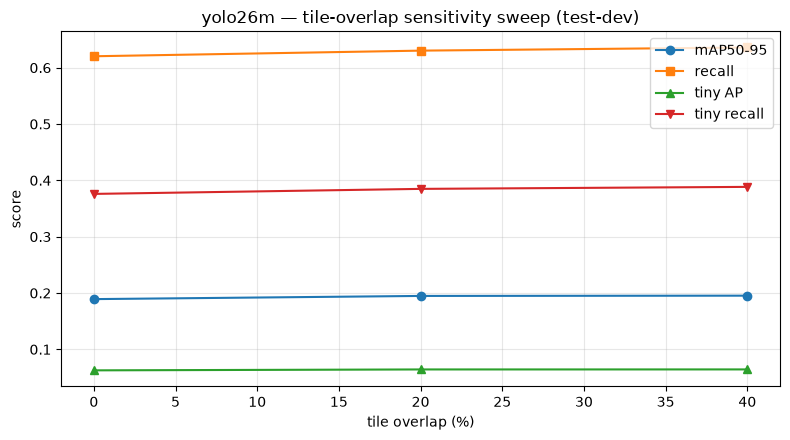

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(overlap_scores["overlap"] * 100, overlap_scores["map50_95"], "o-", label="mAP50-95")
ax.plot(overlap_scores["overlap"] * 100, overlap_scores["recall50_25"], "s-", label="recall")
ax.plot(overlap_scores["overlap"] * 100, overlap_scores["ap_tiny"], "^-", label="tiny AP")
ax.plot(overlap_scores["overlap"] * 100, overlap_scores["recall_tiny"], "v-", label="tiny recall")
ax.set_xlabel("tile overlap (%)")
ax.set_ylabel("score")
ax.set_title("yolo26m — tile-overlap sensitivity sweep (test-dev)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(TILING_DIR / "tiling_overlap_sweep.png", dpi=150)
plt.show()

## 5. Failure analysis (qualitative)

The metrics above show tiling helps tiny/small objects but **regresses on large
objects** (large AP drops by ~0.18–0.21). To make that concrete, three failure
cases are selected deterministically from test-dev (no cherry-picking):

1. **crowding / tiny objects** — the image with the most ground-truth boxes;
2. **large-object regression** — the image containing the single largest object;
3. **tile boundary** — the first image with a large object spanning the `x=640`
   tile edge.

Green = ground truth, red = tiled predictions (conf ≥ 0.25), blue lines = tile
boundaries. Tiling recovers many tiny objects in the crowded scene, while the
large-object and boundary cases show boxes split/clipped across crops or missed
because the object no longer fits a single native-resolution crop.


crowding / tiny: 9999938_00000_d_0000207.jpg


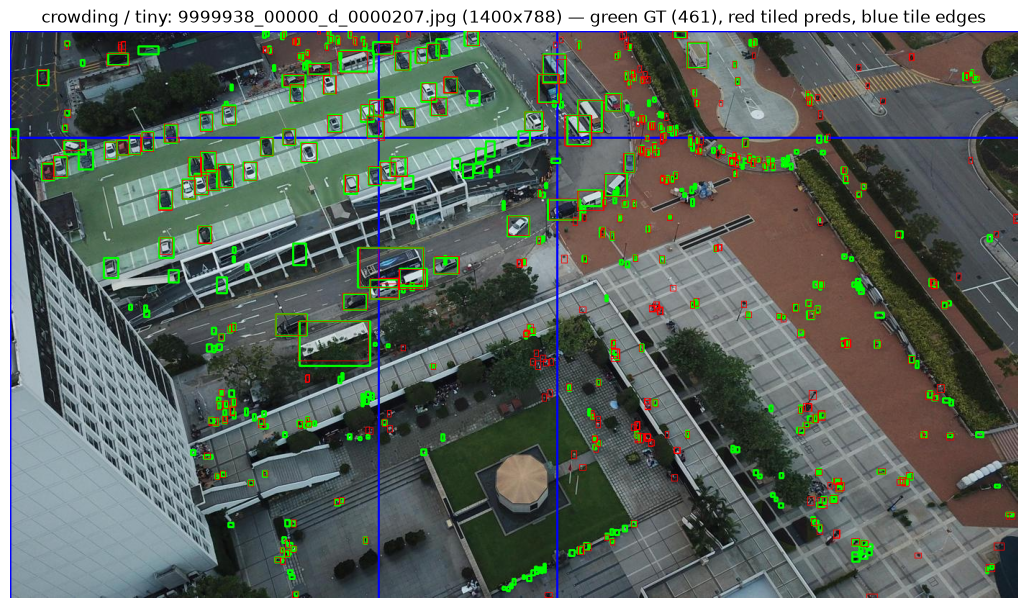

large object: 9999986_00000_d_0000043.jpg


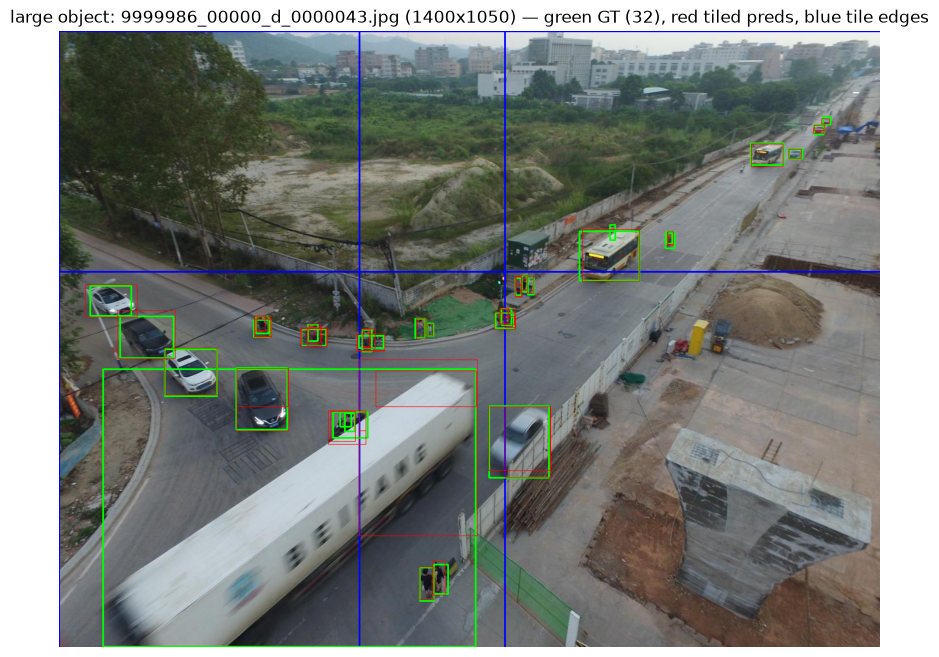

tile boundary: 0000006_00611_d_0000002.jpg


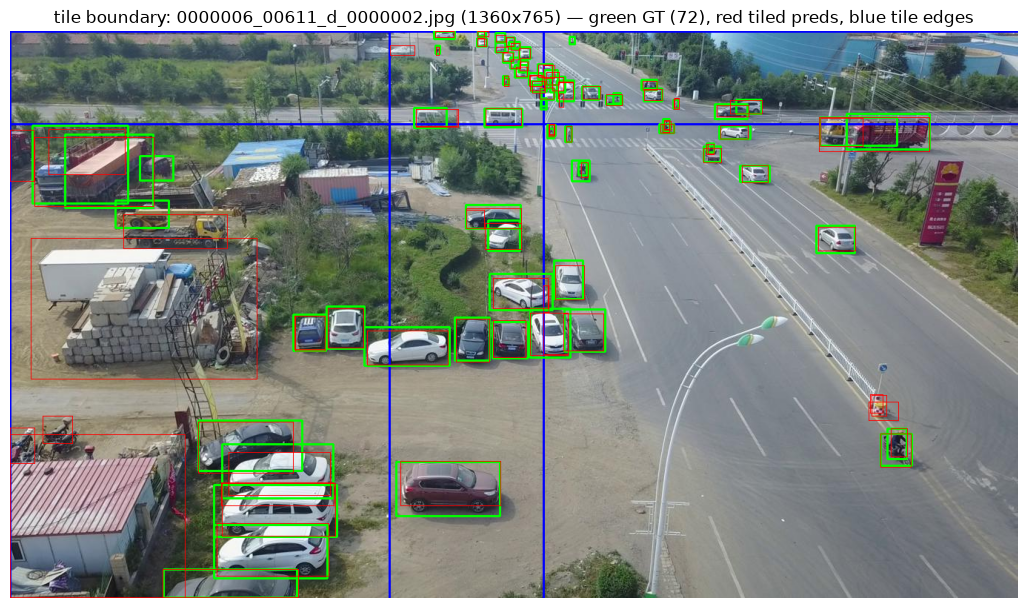

In [11]:
def select_failure_cases(split: str = SPLIT) -> dict[str, Path]:
    """Deterministic failure-case images: crowding, largest object, tile boundary."""
    images, labels = load_split_paths(split)
    cases: dict[str, Path] = {}
    best_crowd = best_tiny = best_large = -1
    for image_path, label_path in zip(images, labels):
        with Image.open(image_path) as im:
            width, height = im.size
        boxes, _ = yolo_to_xyxy(read_yolo_labels(label_path), width, height)
        if len(boxes) == 0:
            continue
        areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
        if len(boxes) > best_crowd:
            best_crowd = len(boxes)
            cases["crowding / tiny"] = image_path
        if int((areas < 256).sum()) > best_tiny:
            best_tiny = int((areas < 256).sum())
        if float(areas.max()) > best_large:
            best_large = float(areas.max())
            cases["large object"] = image_path
        if "tile boundary" not in cases:
            span = (boxes[:, 0] < TILE) & (boxes[:, 2] > TILE) & (areas >= 9216)
            if span.any():
                cases["tile boundary"] = image_path
    return cases


def draw_failure_case(title: str, image_path: Path, model, overlap: float = MAIN_OVERLAP) -> None:
    import cv2

    img = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)
    height, width = img.shape[:2]
    for x0 in tile_starts(width, TILE, overlap):
        cv2.line(img, (x0, 0), (x0, height), (0, 0, 255), 2)
    for y0 in tile_starts(height, TILE, overlap):
        cv2.line(img, (0, y0), (width, y0), (0, 0, 255), 2)
    label_path = (
        image_path.parents[2] / "labels" / image_path.parent.name / f"{image_path.stem}.txt"
    )
    gt_boxes, _ = yolo_to_xyxy(read_yolo_labels(label_path), width, height)
    for x1, y1, x2, y2 in gt_boxes:
        cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
    dets = predict_image_tiled(model, image_path, overlap=overlap, conf=CONF_RECALL)
    for x1, y1, x2, y2, _score, _cls in dets:
        cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (255, 0, 0), 1)
    plt.figure(figsize=(13, 8))
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"{title}: {image_path.name} ({width}x{height}) — "
        f"green GT ({len(gt_boxes)}), red tiled preds, blue tile edges"
    )
    plt.show()


failure_cases = select_failure_cases(SPLIT)
for case_name, case_path in failure_cases.items():
    print(f"{case_name}: {case_path.name}")
    draw_failure_case(case_name, case_path, checkpoints["yolo26m"])

## 6. Summary

* The main tiling condition (640×640 native-resolution crops, 20 % overlap) is
  evaluated for **both** models and written to `runs/tiling/`; every metric
  (overall mAP/recall, tiny and COCO size groups with object counts, mean/p95
  runtime) is produced by the same shared `evaluate_split` used for the baseline.
* The yolo26m overlap sweep (0/20/40 %) reuses the 20 % result and records the
  accuracy/runtime effect of overlap alone.
* To score the later **full-protocol fine-tuned** checkpoints, change `WEIGHTS`
  at the top of the notebook and re-run — no other edit is needed.
* All numbers follow our protocol and are **not** official VisDrone leaderboard
  scores. See `docs/tiling_results.md` for the written report.
